<a href="https://colab.research.google.com/github/Fajtos/forecast-reconciliation/blob/main/lstmlikesim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running nonlinear stress-test simulation...
  Replication 0/50
  Replication 10/50
  Replication 20/50
  Replication 30/50
  Replication 40/50

Results:
Reduction: 100.0% (SD: 0.0%)
μ Correlation: 0.633 (SD: 0.093)


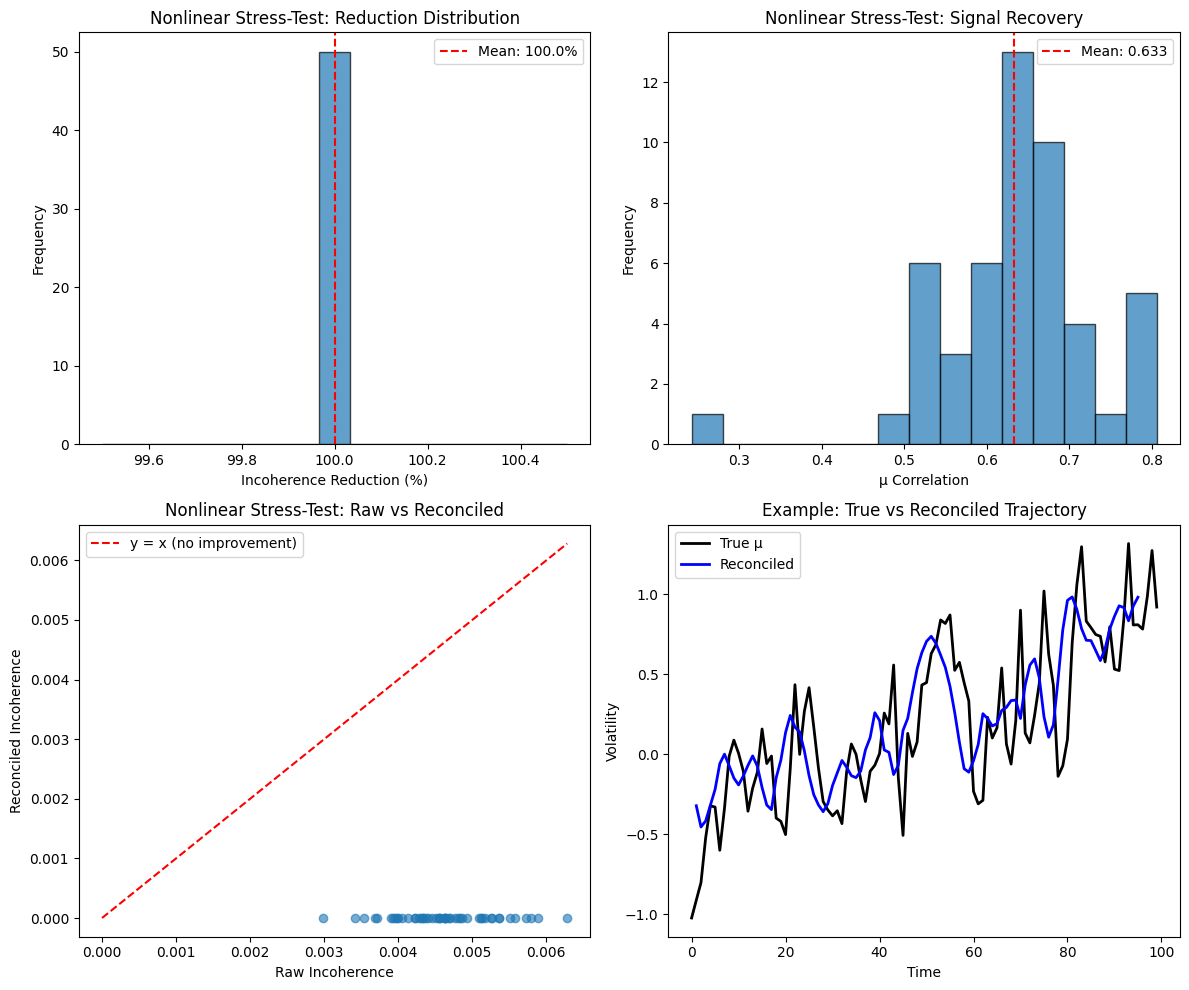


Figure saved as 'nonlinear_stress_test_results.png'


In [ ]:
# ============================================================
# NONLINEAR STRESS-TEST SIMULATION FIGURE (Updated Titles)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

T = 100
H = 5
R = 50
phi = 0.8
sigma_eta = 0.3

def generate_latent_process(T, H, phi, sigma_eta):
    T_total = T + H
    mu = np.zeros(T_total)
    mu[0] = np.random.normal(0, sigma_eta / np.sqrt(1 - phi**2))
    for t in range(1, T_total):
        mu[t] = phi * mu[t-1] + np.random.normal(0, sigma_eta)
    return mu

def generate_nonlinear_forecasts(mu, H, lookback=10):
    T = len(mu) - H
    forecast_matrix = np.full((T, H), np.nan)
    for t in range(T):
        window = mu[t:t+lookback]
        trend = window[-1] - window[0]
        if trend > 0:
            base_forecast = 0.9 * mu[t:t+H] + 0.1 * np.mean(window)
        else:
            base_forecast = 0.7 * mu[t:t+H] + 0.3 * np.mean(window)
        non_linear = 0.05 * np.tanh(2 * (mu[t:t+H] - np.mean(window)))
        epsilon = student_t.rvs(df=5, scale=0.03, size=H)
        delta_h = np.array([0.02, 0.01, -0.01, -0.02, 0.01])
        forecast_matrix[t, :] = base_forecast + non_linear + delta_h + epsilon
    return forecast_matrix

def compute_incoherence(forecast_matrix):
    T, H = forecast_matrix.shape
    total_sse = 0
    count = 0
    for t in range(H, T):
        all_forecasts = []
        for origin in range(max(0, t-H+1), min(t, T-H+1)):
            h = t - origin
            if h < H and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
                all_forecasts.append(forecast_matrix[origin, h])
        if len(all_forecasts) > 1:
            for i in range(len(all_forecasts)):
                for j in range(i+1, len(all_forecasts)):
                    total_sse += (all_forecasts[i] - all_forecasts[j])**2
                    count += 1
    return total_sse / count if count > 0 else 0

def diagonal_reconciliation(forecast_matrix):
    T, H = forecast_matrix.shape
    reconciled = np.full((T, H), np.nan)
    for t in range(H, T):
        all_forecasts = []
        for origin in range(max(0, t-H+1), min(t, T-H+1)):
            h = t - origin
            if h < H and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
                all_forecasts.append(forecast_matrix[origin, h])
        if all_forecasts:
            avg = np.mean(all_forecasts)
            for origin in range(max(0, t-H+1), min(t, T-H+1)):
                h = t - origin
                if h < H and h >= 0 and not np.isnan(forecast_matrix[origin, h]):
                    reconciled[origin, h] = avg
    return reconciled

print("Running nonlinear stress-test simulation...")

raw_incoherence_list = []
reconciled_incoherence_list = []
reduction_list = []
mu_correlation_list = []

for r in range(R):
    if r % 10 == 0:
        print(f"  Replication {r}/{R}")
    mu = generate_latent_process(T, H, phi, sigma_eta)
    mu = mu / np.std(mu) * 0.5
    forecast_matrix = generate_nonlinear_forecasts(mu, H)
    reconciled_matrix = diagonal_reconciliation(forecast_matrix)
    raw_inc = compute_incoherence(forecast_matrix)
    recon_inc = compute_incoherence(reconciled_matrix)
    reduction = (1 - recon_inc / raw_inc) * 100 if raw_inc > 0 else 0
    mu_truth = mu[:T]
    mu_estimated = np.nanmean(reconciled_matrix, axis=1)
    valid_idx = ~np.isnan(mu_estimated)
    if np.sum(valid_idx) > 5:
        corr = np.corrcoef(mu_truth[valid_idx], mu_estimated[valid_idx])[0, 1]
    else:
        corr = np.nan
    raw_incoherence_list.append(raw_inc)
    reconciled_incoherence_list.append(recon_inc)
    reduction_list.append(reduction)
    mu_correlation_list.append(corr)

mu_correlation_list = [c for c in mu_correlation_list if not np.isnan(c)]

print(f"\nResults:")
print(f"Reduction: {np.mean(reduction_list):.1f}% (SD: {np.std(reduction_list):.1f}%)")
print(f"μ Correlation: {np.mean(mu_correlation_list):.3f} (SD: {np.std(mu_correlation_list):.3f})")

# ============================================================
# UPDATED FIGURE WITH CORRECTED TITLES
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Panel 1: Incoherence reduction distribution
ax1 = axes[0, 0]
ax1.hist(reduction_list, bins=15, edgecolor='black', alpha=0.7)
ax1.axvline(np.mean(reduction_list), color='red', linestyle='--',
            label=f'Mean: {np.mean(reduction_list):.1f}%')
ax1.set_xlabel('Incoherence Reduction (%)')
ax1.set_ylabel('Frequency')
ax1.set_title('Nonlinear Stress-Test: Reduction Distribution')
ax1.legend()

# Panel 2: μ correlation distribution
ax2 = axes[0, 1]
ax2.hist(mu_correlation_list, bins=15, edgecolor='black', alpha=0.7)
ax2.axvline(np.mean(mu_correlation_list), color='red', linestyle='--',
            label=f'Mean: {np.mean(mu_correlation_list):.3f}')
ax2.set_xlabel('μ Correlation')
ax2.set_ylabel('Frequency')
ax2.set_title('Nonlinear Stress-Test: Signal Recovery')
ax2.legend()

# Panel 3: Raw vs Reconciled Incoherence
ax3 = axes[1, 0]
ax3.scatter(raw_incoherence_list, reconciled_incoherence_list, alpha=0.6)
ax3.plot([0, max(raw_incoherence_list)], [0, max(raw_incoherence_list)],
         'r--', label='y = x (no improvement)')
ax3.set_xlabel('Raw Incoherence')
ax3.set_ylabel('Reconciled Incoherence')
ax3.set_title('Nonlinear Stress-Test: Raw vs Reconciled')
ax3.legend()

# Panel 4: Example trajectory
ax4 = axes[1, 1]
mu_example = generate_latent_process(T, H, phi, sigma_eta)
mu_example = mu_example / np.std(mu_example) * 0.5
forecast_example = generate_nonlinear_forecasts(mu_example, H)
reconciled_example = diagonal_reconciliation(forecast_example)
mu_estimated_example = np.nanmean(reconciled_example, axis=1)
valid_example = ~np.isnan(mu_estimated_example)

ax4.plot(mu_example[:T], 'k-', linewidth=2, label='True μ')
if np.sum(valid_example) > 5:
    ax4.plot(np.where(valid_example)[0], mu_estimated_example[valid_example],
             'b-', linewidth=2, label='Reconciled')
ax4.set_xlabel('Time')
ax4.set_ylabel('Volatility')
ax4.set_title('Example: True vs Reconciled Trajectory')
ax4.legend()

plt.tight_layout()
plt.savefig('nonlinear_stress_test_results.png', dpi=150)
plt.show()

print("\nFigure saved as 'nonlinear_stress_test_results.png'")